# Experiment 5: the two leakages by group size

The population $\theta$ is the 2010 ACS PUMS with age × race as QID (`AGEP`, `RAC1P`) and disability as sensitive attribute (`DIS`, $k = 2$). The adversary is the benchmark one, whose prior risk is $1/k = 1/2$. In $\theta$, the target's risk is simulated both when the target's record is in the release and when it is not. The statistical leakage is the risk without the target's record over the prior risk, and the differential leakage is the risk with the record over the risk without it. Their product is the inferential leakage, and the figure shows the share of the differential leakage: the logarithm of the differential leakage over that of the inferential leakage.

This notebook produces **Figure 5** of the paper:

- **(a)** `figures/figure5a.pdf`: three pairs of groups with the same base-rate risk $\Phi_q(\theta)$ and very different sizes, against the number of records $n$ and against the expected group size $m = n\,\theta(q,S)$; each point is a mean over $10^5$ releases;
- **(b)** `figures/figure5b.pdf`: all the groups, for $n = 10^3$, $10^4$ and $10^5$; each point is a mean over $10^3$ releases.

The code of the experiment is in `leakages.py`.

In [1]:
import leakages as lk
from build_pums2010 import build_dataset
from common import load_population

data_path = build_dataset()  # downloads and extracts the 2010 ACS PUMS on the first run

Population: 3,061,692 records with no N/A in AGEP, RAC1P, DIS


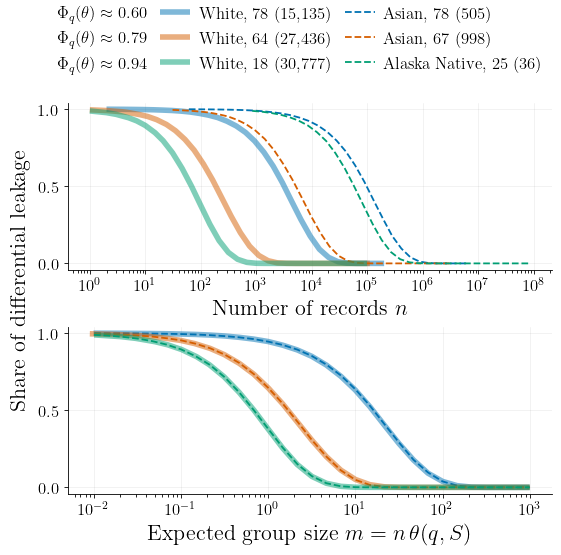

In [2]:
qids, sensitive = ["AGEP", "RAC1P"], "DIS"  # QID: age x race; sensitive attribute: disability
# For each level, the largest group with about that base-rate risk Phi_q(theta), a White group here,
# and the group of a smaller race with the closest base-rate risk: Asian (RAC1P = 6, a few hundred
# records per age) or Alaska Native (RAC1P = 4, a few dozen)
choices = [(0.6, {"RAC1P": "6"}), (0.79, {"RAC1P": "6"}), (0.95, {"RAC1P": "4"})]

theta = load_population(data_path, qids, sensitive)
pairs = lk.pairs(theta, choices)
lk.plot(theta, pairs, "figures/figure5a.pdf")

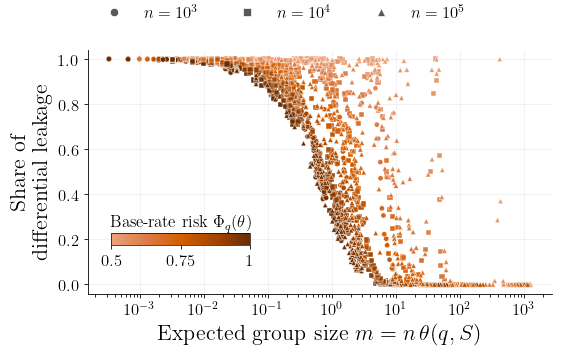

In [3]:
lk.plot_groups(theta, [10**3, 10**4, 10**5], "figures/figure5b.pdf")

## Numbers quoted in the text

Each group of the pairs at the expected group sizes $m = 1$, 10 and 100, i.e. with $n = m / \theta(q,S)$ records; the risks are means over $10^5$ releases (`lk.CURVE_RELEASES`).

In [4]:
lk.pair_table(theta, pairs, grid=[1, 10, 100])

group  records           m  prior risk  \
AGEP RAC1P n                                                             
78   1     202              White, 78    15135    0.998556         0.5   
           2023             White, 78    15135   10.000387         0.5   
           20229            White, 78    15135   99.998927         0.5   
     6     6063             Asian, 78      505    1.000040         0.5   
           60628            Asian, 78      505   10.000072         0.5   
           606276           Asian, 78      505  100.000059         0.5   
64   1     112              White, 64    27436    1.003639         0.5   
           1116             White, 64    27436   10.000541         0.5   
           11159            White, 64    27436   99.996448         0.5   
67   6     3068             Asian, 67      998    1.000056         0.5   
           30678            Asian, 67      998    9.999910         0.5   
           306783           Asian, 67      998  100.000076         0.5   
18   1     99               White, 18    30777    0.995176         0.5   
           995              White, 18    30777   10.002023         0.5   
           9948             White, 18    30777  100.000129         0.5   
25   4     85047    Alaska Native, 25       36    1.000000         0.5   
           850470   Alaska Native, 25       36   10.000000         0.5   
           8504700  Alaska Native, 25       36  100.000000         0.5   

                    out-risk   in-risk  base-rate risk  statistical leakage  \
AGEP RAC1P n                                                                  
78   1     202      0.514545  0.844230        0.604163             1.029091   
           2023     0.550946  0.649998        0.604163             1.101892   
           20229    0.600352  0.604787        0.604163             1.200705   
     6     6063     0.514706  0.844488        0.603960             1.029412   
           60628    0.550488  0.651075        0.603960             1.100977   
           606276   0.600296  0.604719        0.603960             1.200592   
64   1     112      0.615068  0.893774        0.794504             1.230137   
           1116     0.778568  0.797389        0.794504             1.557136   
           11159    0.794504  0.794504        0.794504             1.589007   
67   6     3068     0.615006  0.895620        0.795591             1.230011   
           30678    0.779833  0.797832        0.795591             1.559666   
           306783   0.795591  0.795591        0.795591             1.591182   
18   1     99       0.753196  0.966741        0.944796             1.506392   
           995      0.944405  0.944843        0.944796             1.888810   
           9948     0.944796  0.944796        0.944796             1.889593   
25   4     85047    0.752956  0.966357        0.944444             1.505911   
           850470   0.943822  0.944474        0.944444             1.887644   
           8504700  0.944444  0.944444        0.944444             1.888889   

                    differential leakage  inferential leakage  \
AGEP RAC1P n                                                    
78   1     202                  1.640731             1.688461   
           2023                 1.179786             1.299997   
           20229                1.007387             1.209574   
     6     6063                 1.640718             1.688975   
           60628                1.182722             1.302149   
           606276               1.007368             1.209437   
64   1     112                  1.453129             1.787547   
           1116                 1.024174             1.594778   
           11159                1.000000             1.589007   
67   6     3068                 1.456280             1.791240   
           30678                1.023081             1.595664   
           306783               1.000000             1.591182   
18   1     99                   1.283519             1.93348